# How many ways can you open a jar with one hand?

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cmudrc/design-research-workshop/blob/workshop-three-agent-demos/notebooks/one_handed_jar_brainstorm.ipynb)

Give Workshop PyBot the same design brief twice. First ask for complete concepts, then ask it to explore one function at a time. Track how many different mechanisms appear and choose a concept to test.

Run the numbered sections in order. The workshop rules run on a CPU without an API key.

## 1. Set up

Run the install cell in Colab. If you already installed the workshop package in your local Jupyter environment, start with section 2.

In [ ]:
# @title Install the workshop package { display-mode: "form" }
%pip -q install "design-research-workshop @ git+https://github.com/cmudrc/design-research-workshop.git@workshop-three-agent-demos"

## 2. Read the brief and predict the outcome

The chart gives PyBot three choices for each function. Before you run the two prompts, predict which mechanism will appear most often. How many concepts would you need to see every option at least once?

Choose 1 to 24 ideas for each run. The seed breaks ties between equally ranked combinations.

In [1]:
# @title Load the brief and set the number of ideas { display-mode: "form" }
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from design_research.problems import get_problem
from design_research_workshop import workshop_client
from design_research_workshop.brainstorm import JAR_OPENER, PROBLEM_ID, run_brainstorm

count = 6  # @param {type: "integer"}
seed = 7  # @param {type: "integer"}
functions = tuple(JAR_OPENER.functions)

def table(headings, rows):
    lines = [headings, ["---"] * len(headings), *rows]
    display(Markdown("\n".join("| " + " | ".join(map(str, line)) + " |" for line in lines)))

def show_ideas(result):
    rows = [
        [i, *[idea[name] for name in functions]]
        for i, idea in enumerate(result["concepts"], 1)
    ]
    print(f"PyBot used the {result['strategy']} rule.")
    table(["Idea", *functions], rows)

print(JAR_OPENER.statement)
print(f"Adapted from the Design Research Problems brief ‘{get_problem(PROBLEM_ID).metadata.title}’.")
table(["Function", "Options in catalog order"],
      [[name, " · ".join(options)] for name, options in JAR_OPENER.functions.items()])

Design a countertop device that lets someone working with one hand open a screw-top food jar. Consider how the person positions the jar, breaks the lid seal, and takes the jar back out.
Adapted from the Design Research Problems brief ‘One-Handed Lidded Container Opening’.


| Function | Options in catalog order |
| --- | --- |
| Hold the jar | High-friction cradle · Counter-mounted V-block · Self-centering clamp |
| Grip the lid | Tapered rubber socket · Lever-lock strap · Spring-loaded jaws |
| Turn the lid | T-handle · Offset lever · Ratcheting arm |

## 3. Ask for complete concepts

Read across one row to see a complete concept. Which parts change between ideas 1 and 2?

In [2]:
prompt_a = "Suggest complete one-handed jar opener concepts."
print(prompt_a)
with workshop_client() as client:
    direct = run_brainstorm(client, prompt_a, count=count, seed=seed)
show_ideas(direct)

Suggest complete one-handed jar opener concepts.
PyBot used the direct rule.


| Idea | Hold the jar | Grip the lid | Turn the lid |
| --- | --- | --- | --- |
| 1 | High-friction cradle | Tapered rubber socket | T-handle |
| 2 | Counter-mounted V-block | Tapered rubber socket | T-handle |
| 3 | High-friction cradle | Lever-lock strap | T-handle |
| 4 | High-friction cradle | Tapered rubber socket | Offset lever |
| 5 | Self-centering clamp | Tapered rubber socket | T-handle |
| 6 | High-friction cradle | Spring-loaded jaws | T-handle |

## 4. Ask for a function-first brainstorm

Change the framing. Keep the brief, number of ideas, seed, and mechanism chart the same. Look for the first idea that uses a different mechanism for all three functions.

In [3]:
prompt_b = (
    "Brainstorm one-handed jar openers function by function. Vary how each "
    "concept holds the jar, grips the lid, and turns the lid."
)
print(prompt_b)
with workshop_client() as client:
    function_first = run_brainstorm(client, prompt_b, count=count, seed=seed)
show_ideas(function_first)

Brainstorm one-handed jar openers function by function. Vary how each concept holds the jar, grips the lid, and turns the lid.
PyBot used the function-first rule.


| Idea | Hold the jar | Grip the lid | Turn the lid |
| --- | --- | --- | --- |
| 1 | High-friction cradle | Tapered rubber socket | T-handle |
| 2 | Counter-mounted V-block | Lever-lock strap | Offset lever |
| 3 | Self-centering clamp | Spring-loaded jaws | Ratcheting arm |
| 4 | Counter-mounted V-block | Tapered rubber socket | T-handle |
| 5 | High-friction cradle | Lever-lock strap | Offset lever |
| 6 | High-friction cradle | Spring-loaded jaws | Ratcheting arm |

## 5. Count the mechanisms in each set

The direct rule tries combinations near the top of the chart first. The function-first rule gives priority to mechanisms missing from earlier ideas. Count each mechanism once within its function. How quickly does each prompt cover the chart?

Mechanism coverage


Direct: 8 distinct mechanisms across 6 concepts.
Function-first: 9 distinct mechanisms across 6 concepts.


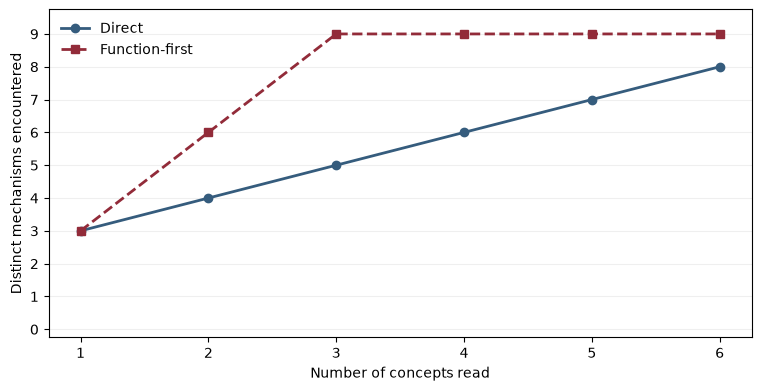

In [4]:
def coverage(ideas):
    seen = set()
    counts = []
    for idea in ideas:
        seen.update(idea.items())
        counts.append(len(seen))
    return counts

print("Mechanism coverage")
fig, ax = plt.subplots(figsize=(7.5, 3.8), layout="constrained")
for result, label, color, line, marker in (
    (direct, "Direct", "#355C7D", "-", "o"),
    (function_first, "Function-first", "#922B39", "--", "s"),
):
    totals = coverage(result["concepts"])
    steps = range(1, len(totals) + 1)
    ax.plot(steps, totals, label=label, lw=2, color=color, linestyle=line, marker=marker)
    print(f"{label}: {totals[-1]} distinct mechanisms across {len(totals)} concepts.")
option_count = sum(map(len, JAR_OPENER.functions.values()))
ax.set(xlabel="Number of concepts read", ylabel="Distinct mechanisms encountered",
       xticks=range(1, len(direct["concepts"]) + 1), yticks=range(0, option_count + 1),
       ylim=(-0.25, option_count + 0.75))
ax.grid(axis="y", alpha=0.2)
ax.legend(frameon=False)
plt.show()

## 6. Change one design decision

Suppose a teammate wants a ratcheting arm in every concept. Type a follow-up and inspect the bot’s response. Try “Avoid the T-handle and show me five ideas” or “Try a direct brainstorm with four ideas.” To keep or exclude a mechanism, use one of the names in the chart.

The Python call below passes the previous exchange to the same bot that served the first two cases. Its reply shows which rule handled the follow-up.

In [5]:
# @title Edit the follow-up prompt { display-mode: "form" }
import json
from design_research_workshop import WorkshopPyBot

follow_up = "Keep the ratcheting arm and show me three concepts."  # @param {type: "string"}
history = [
    {"role": "user", "content": f"{prompt_b}\nConcept count: {count}\nSeed: {seed}"},
    {"role": "assistant", "content": json.dumps(function_first)},
]
print(follow_up)
try:
    reply = WorkshopPyBot().reply(follow_up, history=history)
except ValueError as error:
    print(f"PyBot needs a change to the request. {error}")
else:
    print(f"Selected rule: {reply.rule or 'clarification'} ({reply.reason}).")
    if reply.rule == "jar-opener":
        show_ideas(reply.content)
        for step in reply.content["trace"]:
            gained = ", ".join(step["new_functions"]) or "none"
            print(f"Idea {step['idea']} introduced a new mechanism for: {gained}.")
    else:
        print(reply.content.get("question") or json.dumps(reply.content, indent=2))

Keep the ratcheting arm and show me three concepts.
Selected rule: jar-opener (follow-up on the preceding task).
PyBot used the function-first rule.


| Idea | Hold the jar | Grip the lid | Turn the lid |
| --- | --- | --- | --- |
| 1 | High-friction cradle | Tapered rubber socket | Ratcheting arm |
| 2 | Counter-mounted V-block | Lever-lock strap | Ratcheting arm |
| 3 | Self-centering clamp | Spring-loaded jaws | Ratcheting arm |

Idea 1 introduced a new mechanism for: Hold the jar, Grip the lid, Turn the lid.
Idea 2 introduced a new mechanism for: Hold the jar, Grip the lid.
Idea 3 introduced a new mechanism for: Hold the jar, Grip the lid.


## Discuss

Pick one concept. Walk through placing the jar, engaging the lid, and retrieving the open jar using only one hand. Where might the person need a second hand? Sketch a change or propose a test that would reveal the problem.

What design principle is missing from the mechanism chart? Where would you add it, and how would that change your interpretation of the coverage plot?